# YOLO 3개 부류 Fine-tuning (ML 과제)

흐름: 데이터 불러오기 → 학습 → 성능 평가 → 5초 동영상 감지+추적 → 결과물 다운로드

In [1]:
!nvidia-smi
!pip install -q ultralytics roboflow
import ultralytics; ultralytics.checks()

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)


## 1. 데이터 불러오기
**Roboflow** — 라벨링 끝낸 뒤 Versions → Export → 포맷 `YOLOv11` 

In [ ]:
from roboflow import Roboflow
rf = Roboflow(api_key="여기에_API_KEY")
project = rf.workspace("여기에_workspace").project("여기에_project")
dataset = project.version(1).download("yolov11")
DATA_YAML = f"{dataset.location}/data.yaml"
print(DATA_YAML)

In [ ]:
# data.yaml 확인 (nc: 3, names: 3개 부류인지 확인)
print(open(DATA_YAML).read())

## 2. 학습 (사전학습 모델 → 3개 부류로 fine-tuning)

In [3]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")   # COCO 사전학습 가중치. 'yolo26n.pt'로 바꿔도 됩니다
results = model.train(
    data=DATA_YAML,
    epochs=100,       # 데이터가 적으면 100 정도, 시간이 없으면 50
    imgsz=640,
    batch=16,
    patience=20,      # 20 epoch 동안 개선 없으면 조기 종료
    project="/content/runs",
    name="3class",
    exist_ok=True,
)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=3class, nbs=64, nms=None, opset=None, optimize=False, optimize

## 3. 성능 평가

In [4]:
best = YOLO("/content/runs/3class/weights/best.pt")
m = best.val(data=DATA_YAML)
print(f"mAP50     : {m.box.map50:.3f}")
print(f"mAP50-95  : {m.box.map:.3f}")
print(f"Precision : {m.box.mp:.3f}")
print(f"Recall    : {m.box.mr:.3f}")
for i, name in best.names.items():
    print(f"  {name:>12s}  AP50={m.box.ap50[i]:.3f}  AP50-95={m.box.ap[i]:.3f}")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1301.1±393.0 MB/s, size: 26.9 KB)
val: Scanning /content/dataset/valid/labels.cache... 34 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 34/34 11.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.8it/s 1.1s
                   all         34         34       0.99          1      0.995      0.929
                 mouse         11         11      0.987          1      0.995      0.995
                   mug         11         11      0.987          1      0.995      0.977
                tissue         12         12      0.996          1      0.995      0.816
Speed: 3.4ms preprocess, 7.1ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to /content/runs/detect/val
mAP50     : 0.9

results.png


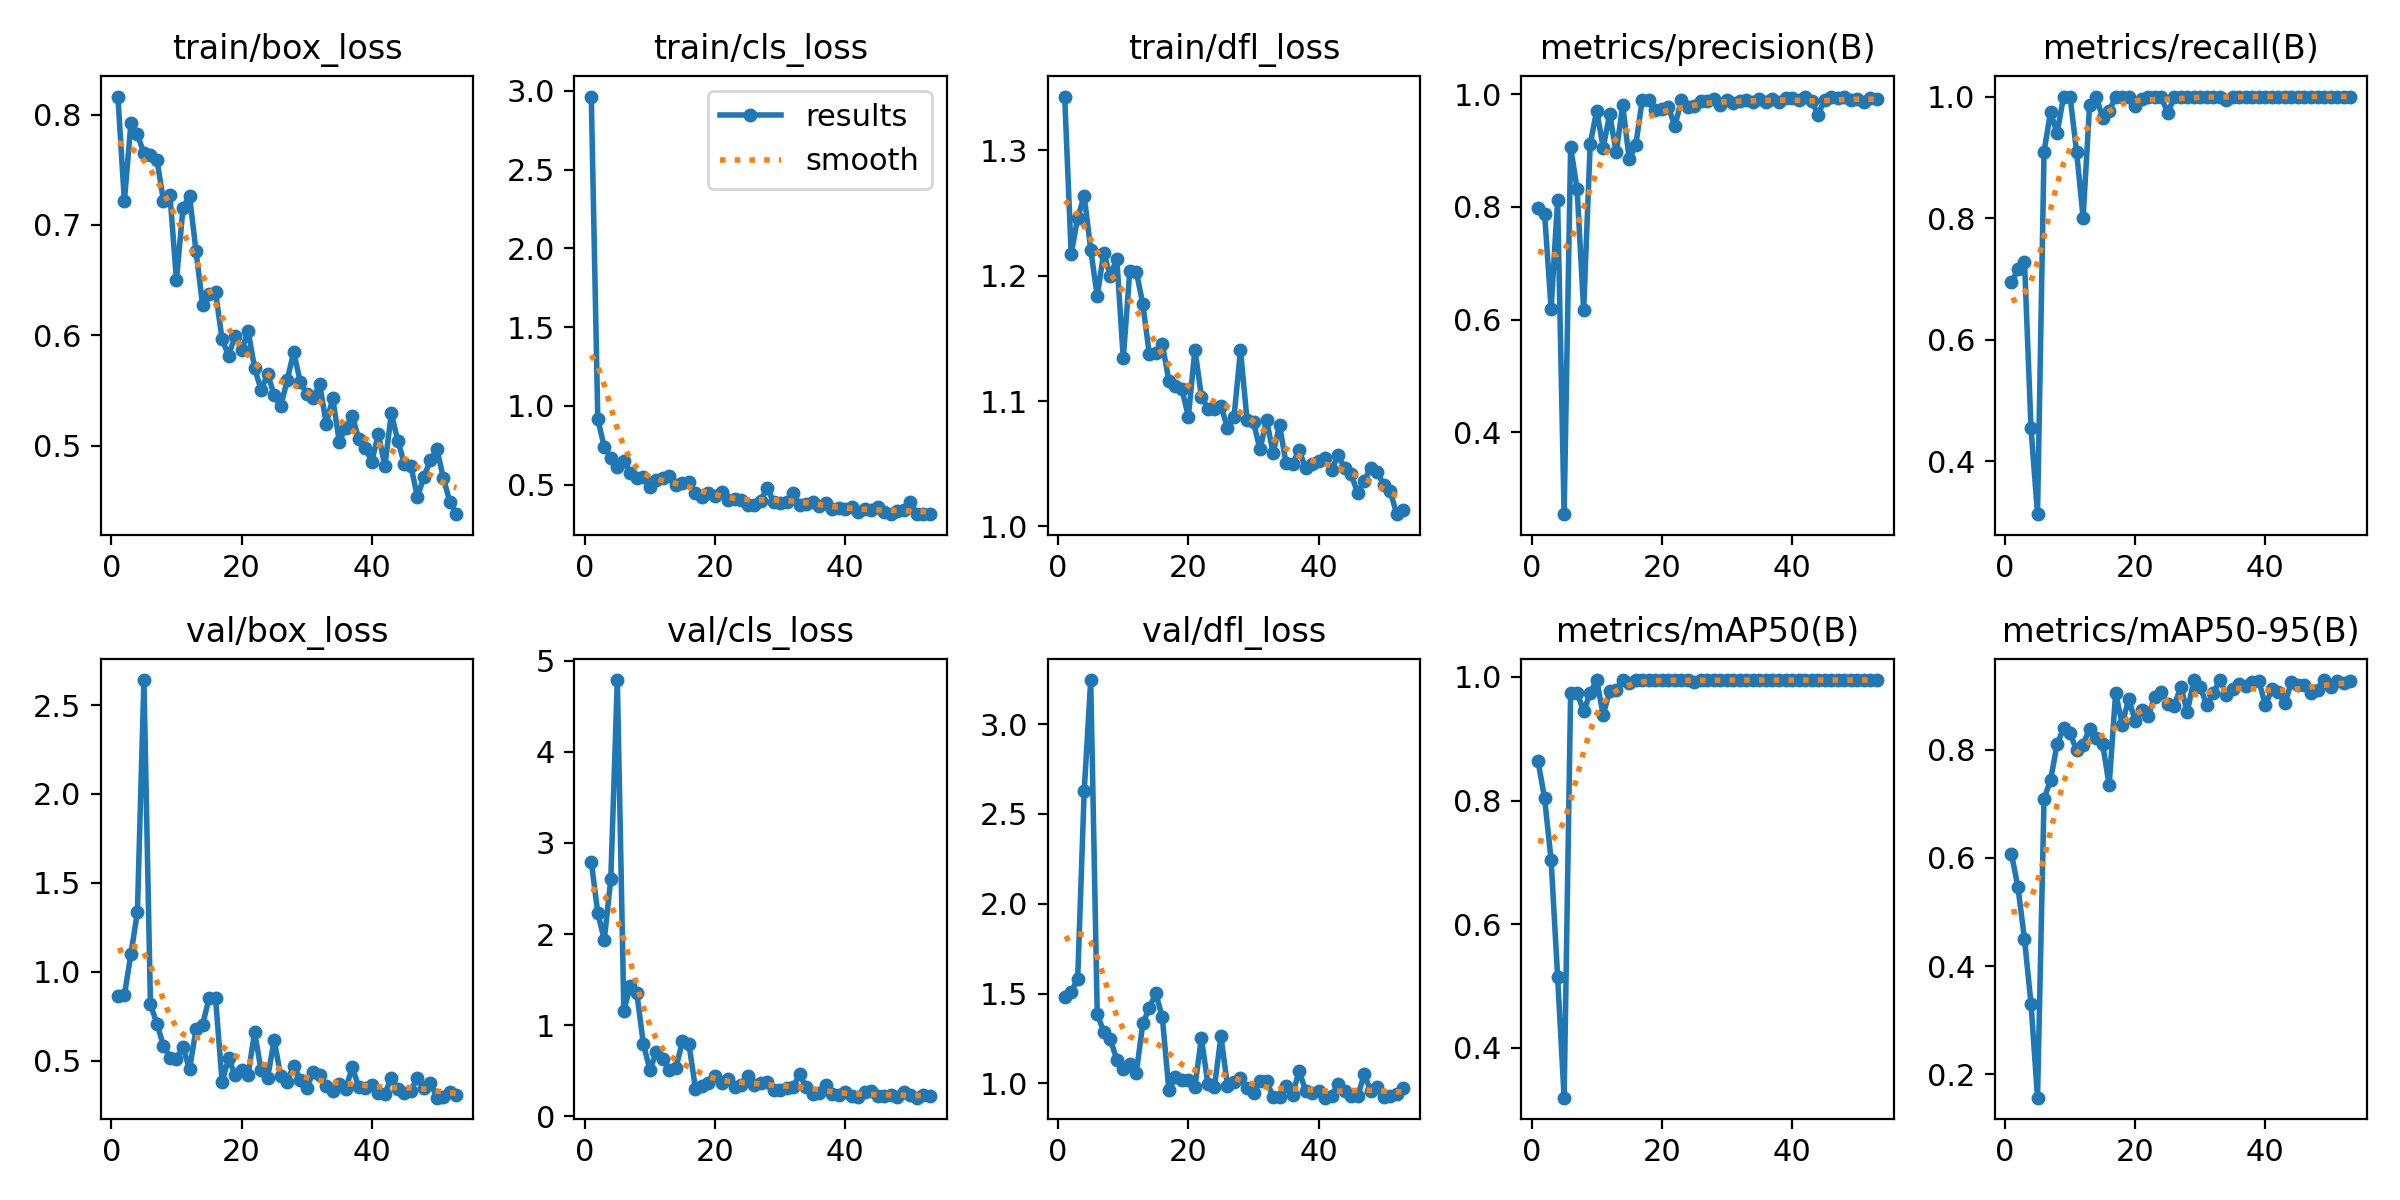

confusion_matrix.png


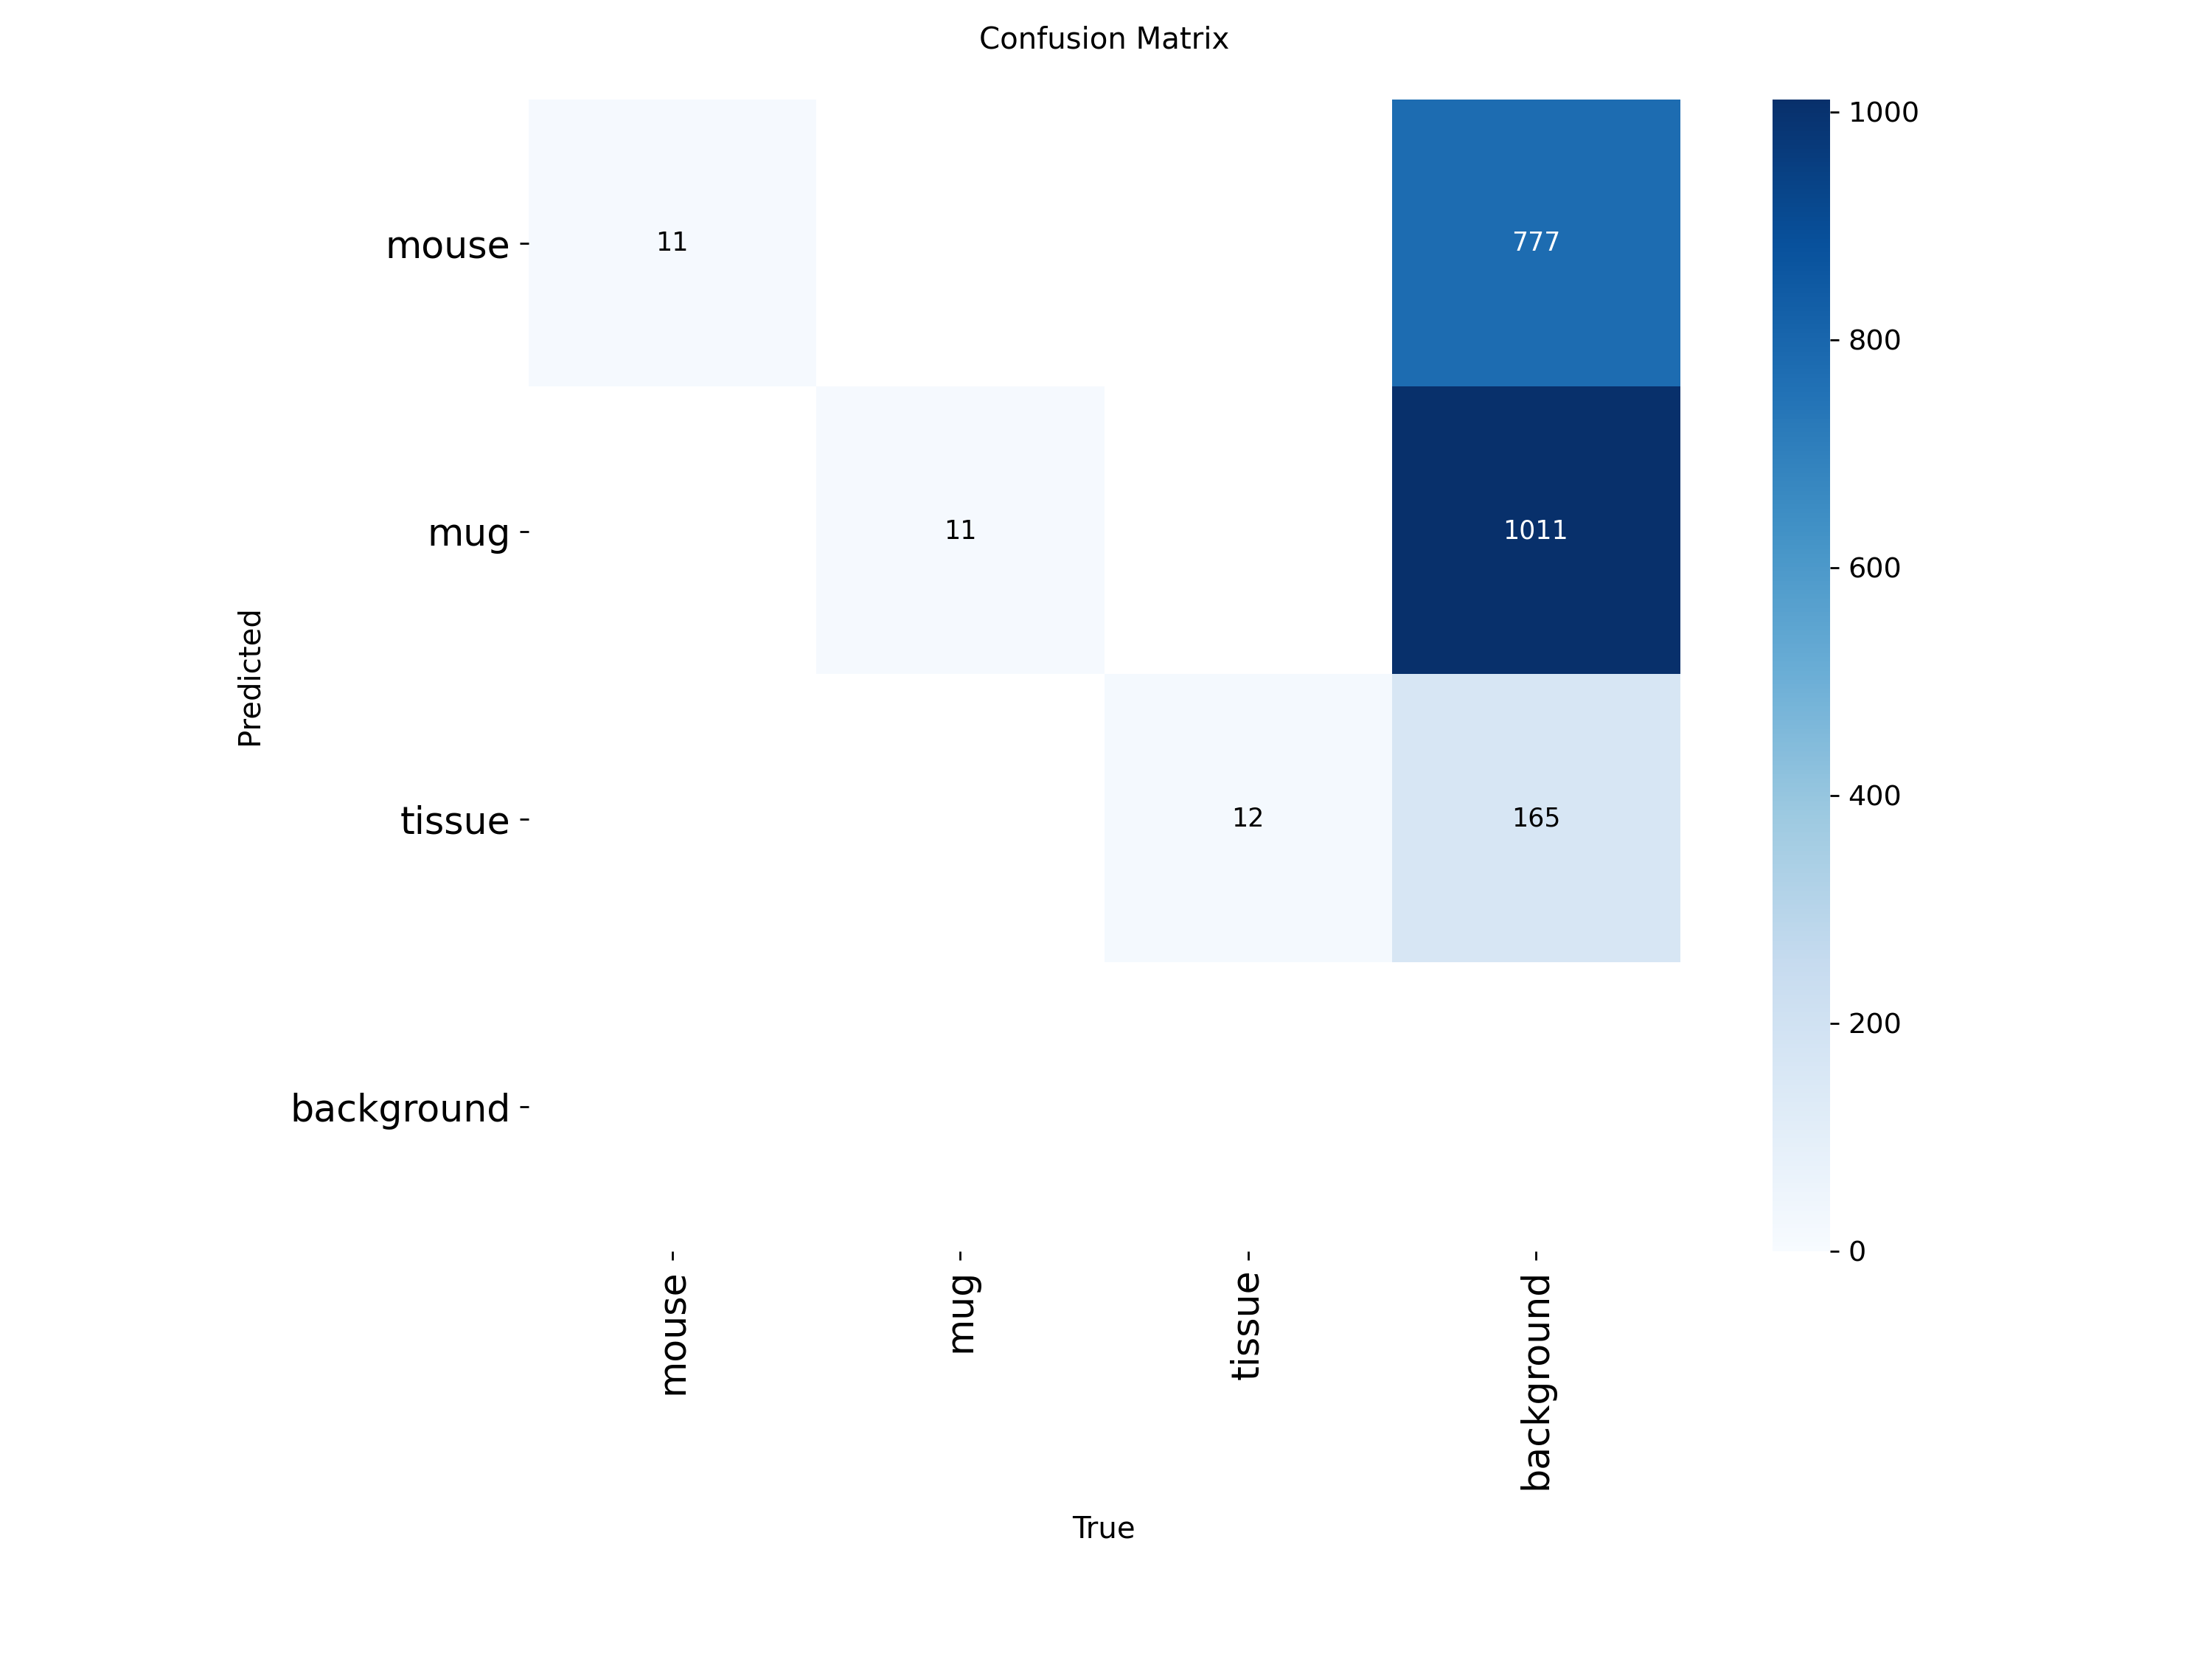

BoxPR_curve.png


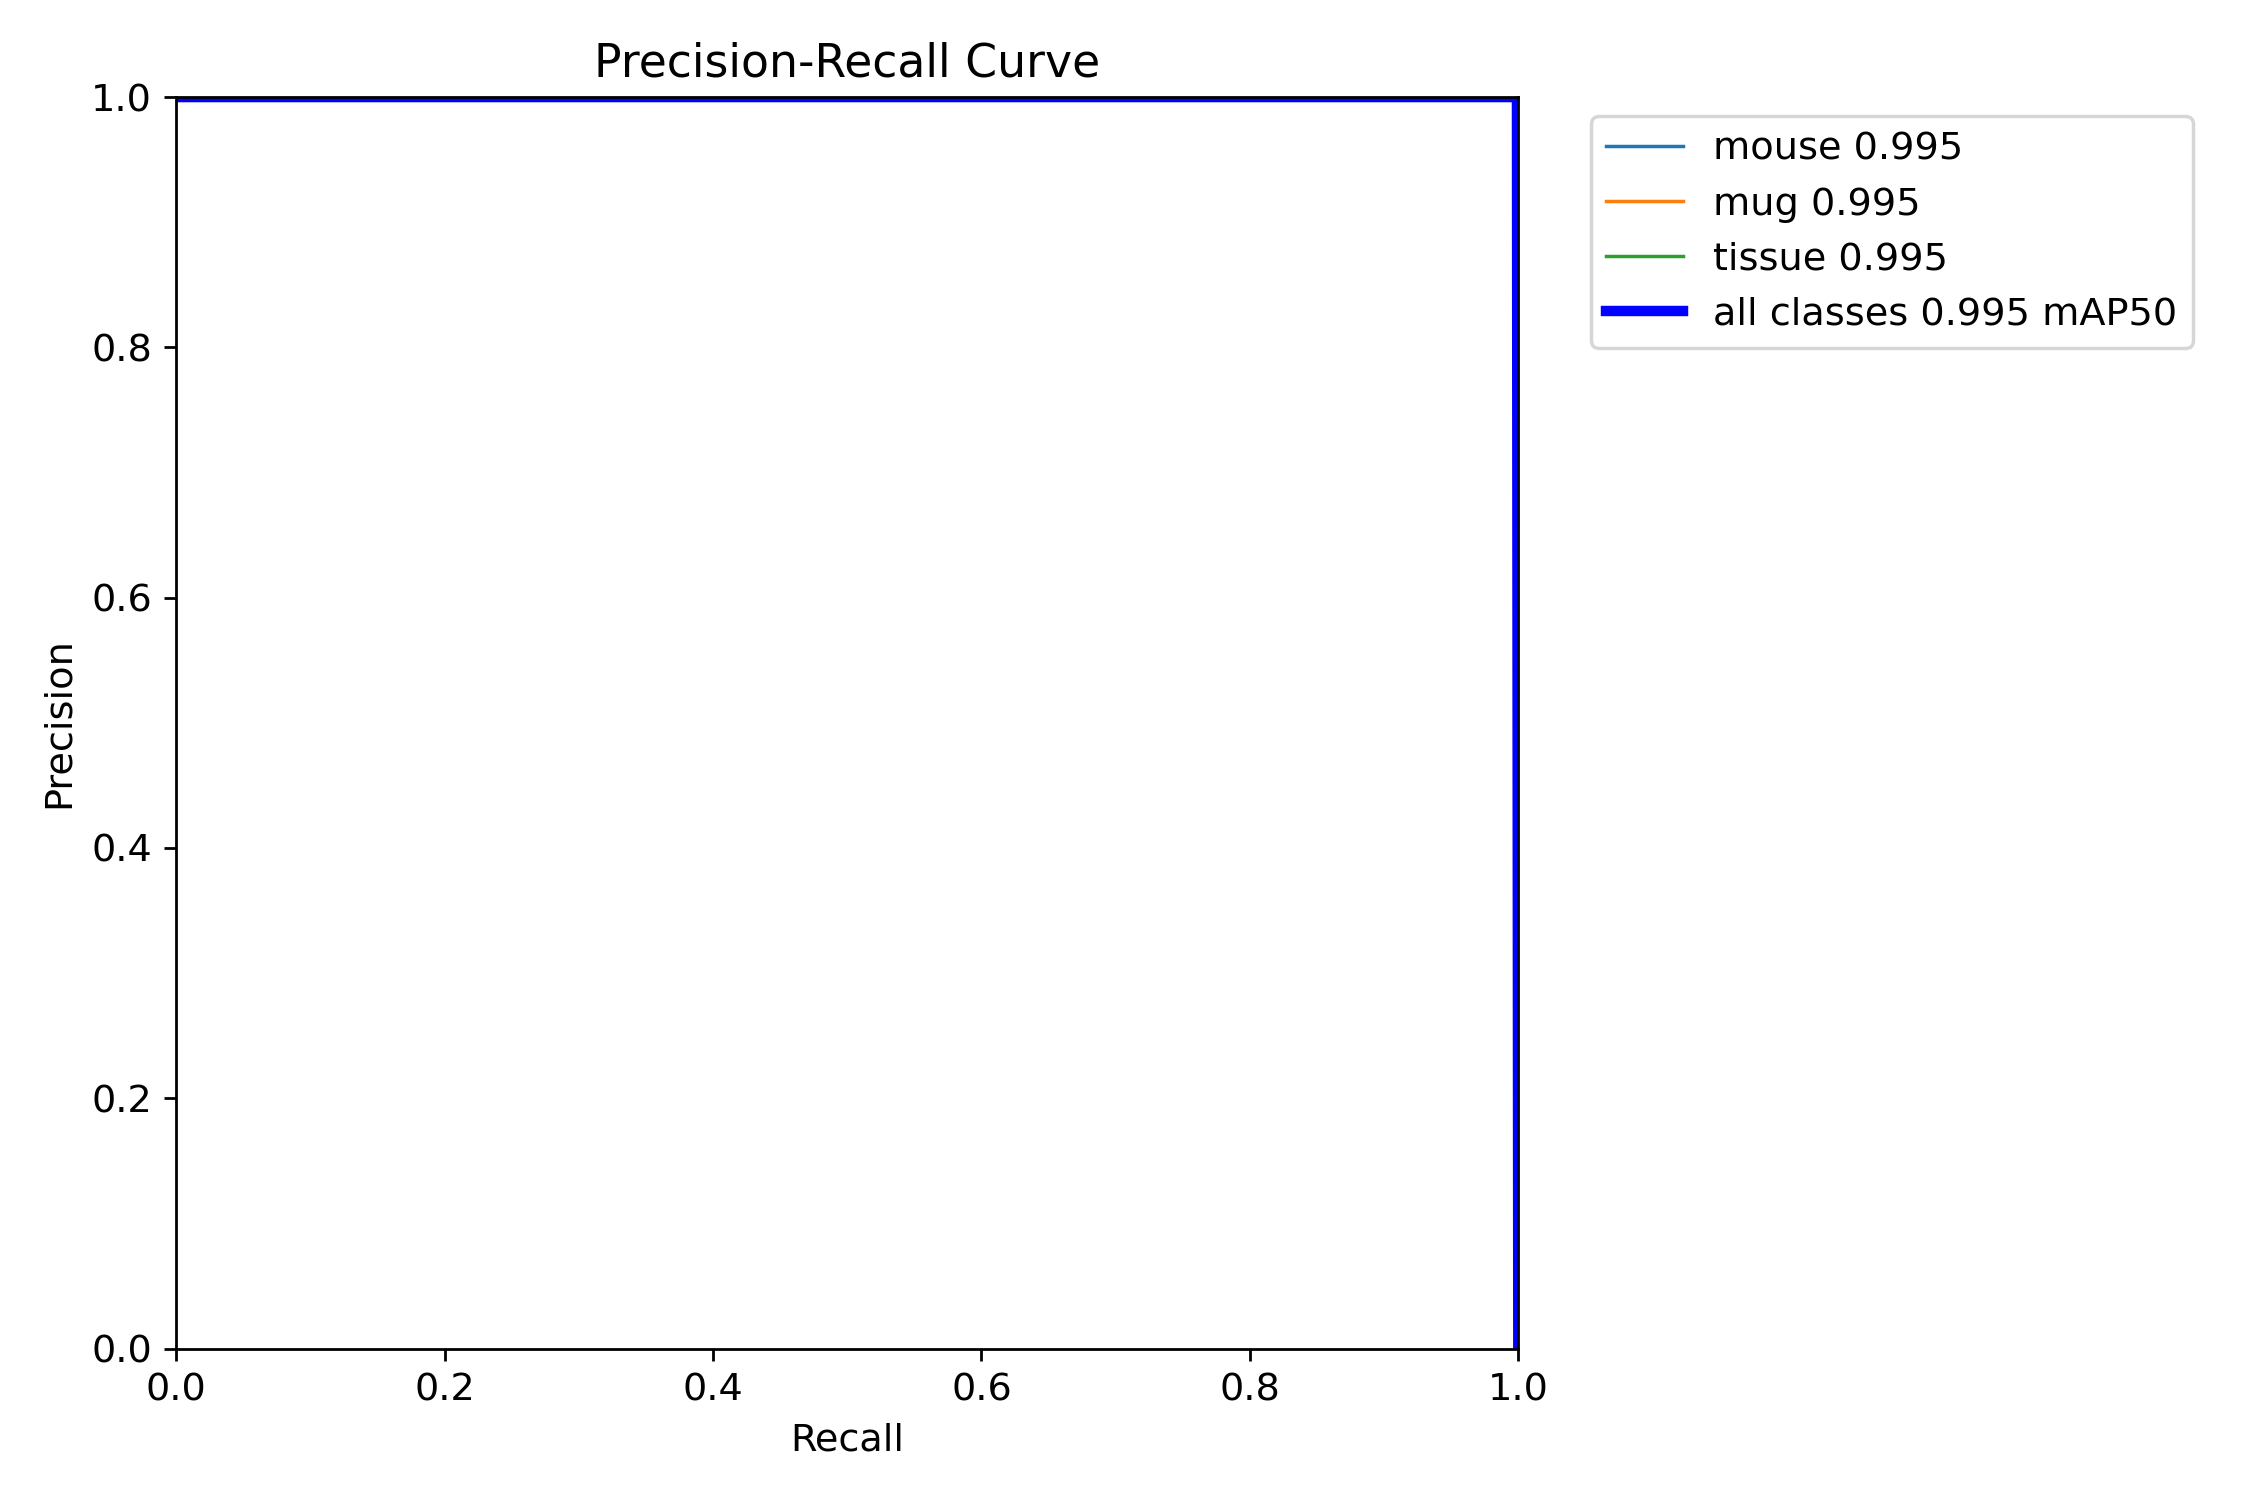

val_batch0_pred.jpg


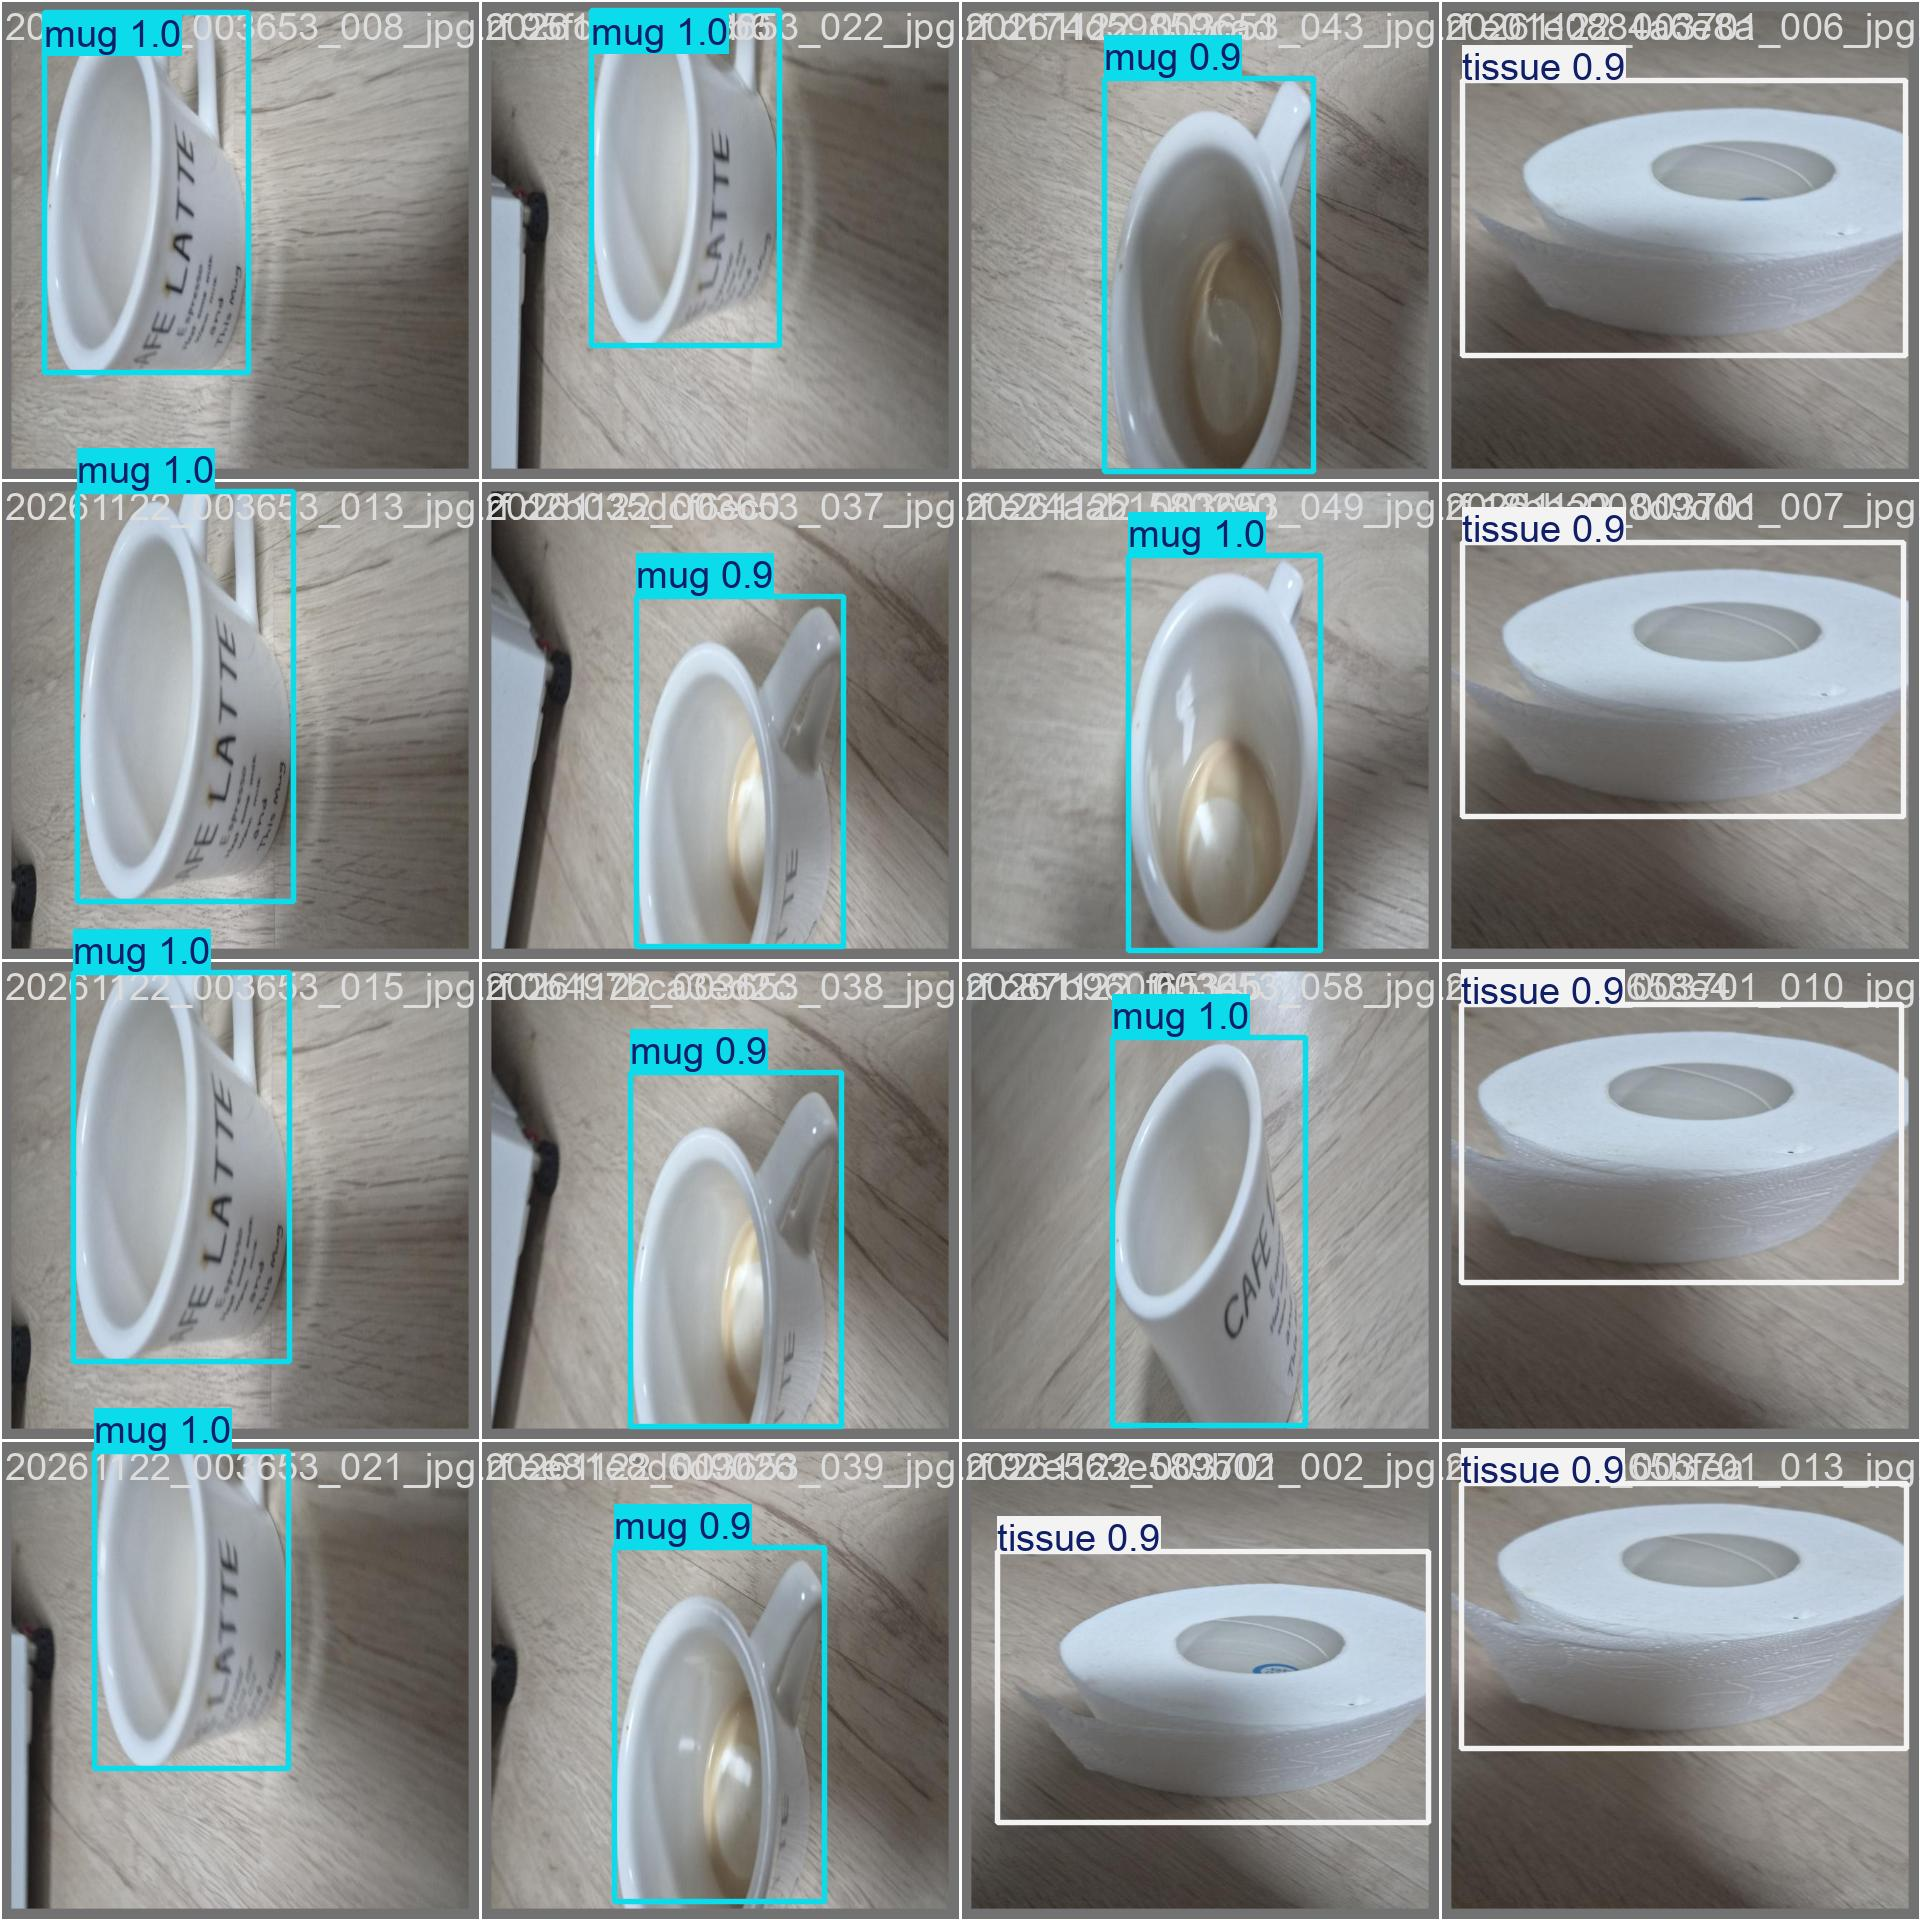

In [5]:
from IPython.display import Image, display
d = "/content/runs/3class"
for f in ["results.png", "confusion_matrix.png", "BoxPR_curve.png", "val_batch0_pred.jpg"]:
    try:
        print(f); display(Image(f"{d}/{f}", width=800))
    except Exception as e:
        print("  (없음)", e)

## 4. 동영상 감지 + 추적
3개 물체가 함께 나오는 영상, 앞 5초만 잘라서 사용.

In [6]:
!ffmpeg -y -loglevel error -i /content/input.mp4 -t 5 -c:v libx264 -an /content/clip5s.mp4
!ffprobe -v error -show_entries format=duration -of csv=p=0 /content/clip5s.mp4

5.000000


In [ ]:
# 추적 + 이동 궤적(trajectory) 그리기
import cv2
from collections import defaultdict

cap = cv2.VideoCapture("/content/clip5s.mp4")
fps = cap.get(cv2.CAP_PROP_FPS) or 30
w, h = int(cap.get(3)), int(cap.get(4))
out = cv2.VideoWriter("/content/track_raw.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
history = defaultdict(list)

while True:
    ok, frame = cap.read()
    if not ok:
        break
    r = best.track(frame, persist=True, tracker="bytetrack.yaml", conf=0.4, verbose=False)[0]
    img = r.plot()
    if r.boxes.id is not None:
        for (x, y, bw, bh), tid in zip(r.boxes.xywh.cpu().numpy(), r.boxes.id.int().cpu().tolist()):
            history[tid].append((int(x), int(y)))
            history[tid] = history[tid][-60:]
            for p, q in zip(history[tid][:-1], history[tid][1:]):
                cv2.line(img, p, q, (0, 255, 255), 3)
    out.write(img)

cap.release(); out.release()
# GitHub/브라우저에서 재생되도록 H.264로 변환
!ffmpeg -y -loglevel error -i /content/track_raw.mp4 -c:v libx264 -pix_fmt yuv420p /content/result_tracking.mp4
print("완료: /content/result_tracking.mp4")

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 236ms
Prepared 1 package in 56ms
Installed 1 package in 2ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.6s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

완료: /content/result_tracking.mp4


In [8]:
from IPython.display import HTML
from base64 import b64encode
v = b64encode(open("/content/result_tracking.mp4", "rb").read()).decode()
HTML(f'<video width=640 controls><source src="data:video/mp4;base64,{v}" type="video/mp4"></video>')

## 5. 결과물 (GitHub)

In [11]:
!mkdir -p /content/submit
!cp /content/runs/3class/weights/best.pt /content/runs/3class/*.png /content/runs/3class/results.csv /content/result_tracking.mp4 /content/submit/ 2>/dev/null
!cp {DATA_YAML} /content/submit/
!cd /content && zip -qr submit.zip submit && ls -lh submit
from google.colab import files
files.download("/content/submit.zip")

total 9.6M
-rw-r--r-- 1 root root 5.3M Nov 21 17:00 best.pt
-rw-r--r-- 1 root root 154K Nov 21 17:00 BoxF1_curve.png
-rw-r--r-- 1 root root 125K Nov 21 17:00 BoxP_curve.png
-rw-r--r-- 1 root root  84K Nov 21 17:00 BoxPR_curve.png
-rw-r--r-- 1 root root 112K Nov 21 17:00 BoxR_curve.png
-rw-r--r-- 1 root root 116K Nov 21 17:00 confusion_matrix_normalized.png
-rw-r--r-- 1 root root 111K Nov 21 17:00 confusion_matrix.png
-rw-r--r-- 1 root root  275 Nov 21 17:00 data.yaml
-rw-r--r-- 1 root root 6.4K Nov 21 17:00 results.csv
-rw-r--r-- 1 root root 261K Nov 21 17:00 results.png
-rw-r--r-- 1 root root 3.3M Nov 21 17:00 result_tracking.mp4


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>